# SpaceX Falcon 9 — Exploratory Data Analysis with Data Visualization

**Objective:** use scatter plots, bar charts and line charts to find the relationships between flight number, payload mass, launch site, orbit, year and landing success, and prepare the features for the machine learning model.

In [1]:
import piplite
await piplite.install(['numpy', 'pandas', 'seaborn'])

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from js import fetch
import io, json

async def get_text(url):
    resp = await fetch(url)
    if not resp.ok:
        raise Exception(f"HTTP {resp.status} for {url}")
    return await resp.text()

async def get_json(url):
    return json.loads(await get_text(url))

async def get_csv(url):
    return pd.read_csv(io.StringIO(await get_text(url)))

In [4]:
df = await get_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


### Flight Number vs. Payload Mass (coloured by landing outcome)

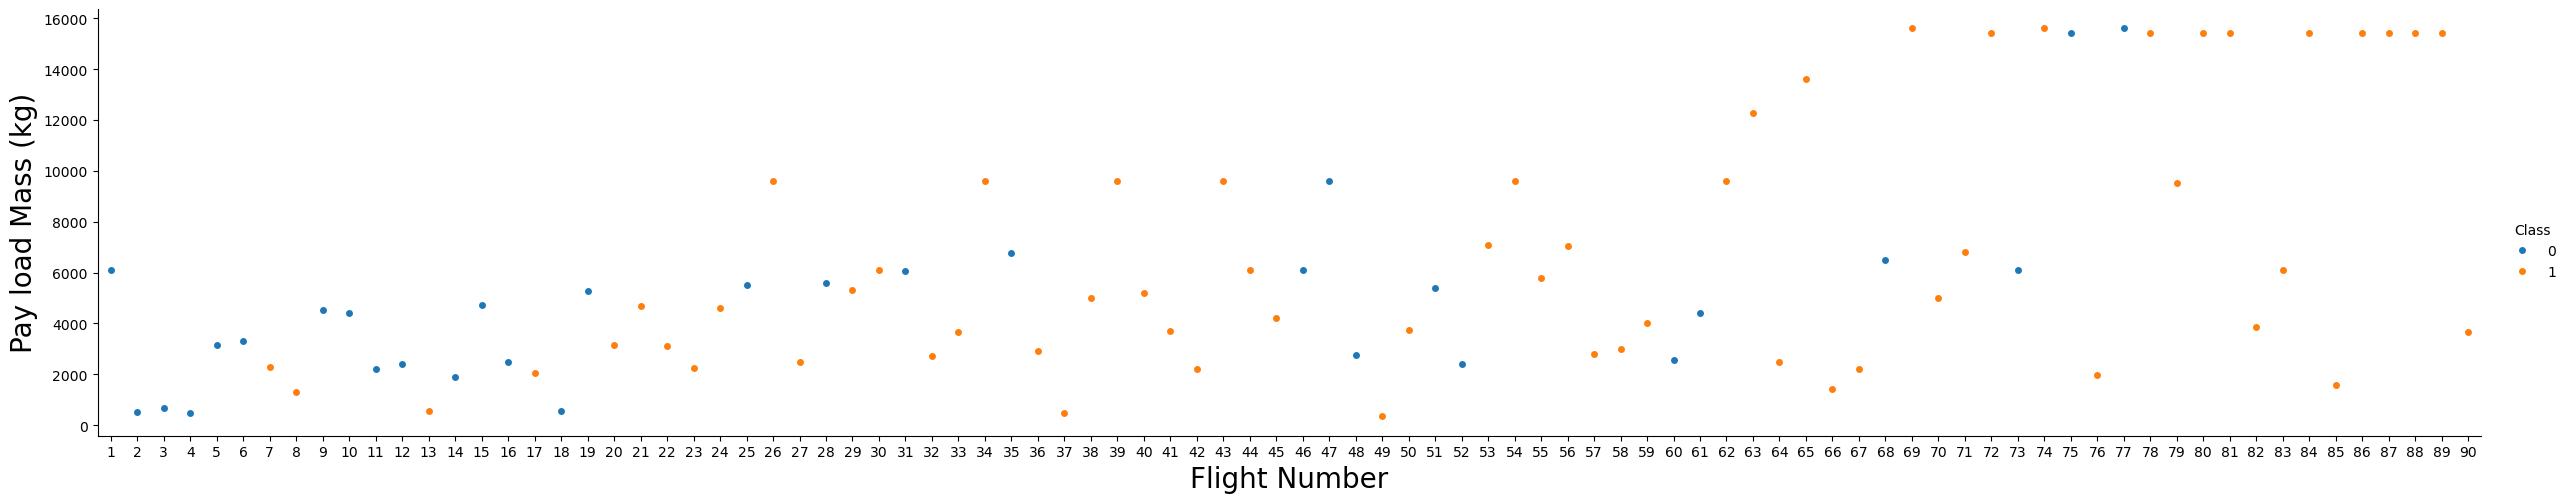

In [5]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20)
plt.ylabel("Pay load Mass (kg)", fontsize=20)
plt.show()

As the flight number increases, the first stage is more likely to land successfully; heavier payloads do not prevent success.

## Task 1: Relationship between Flight Number and Launch Site

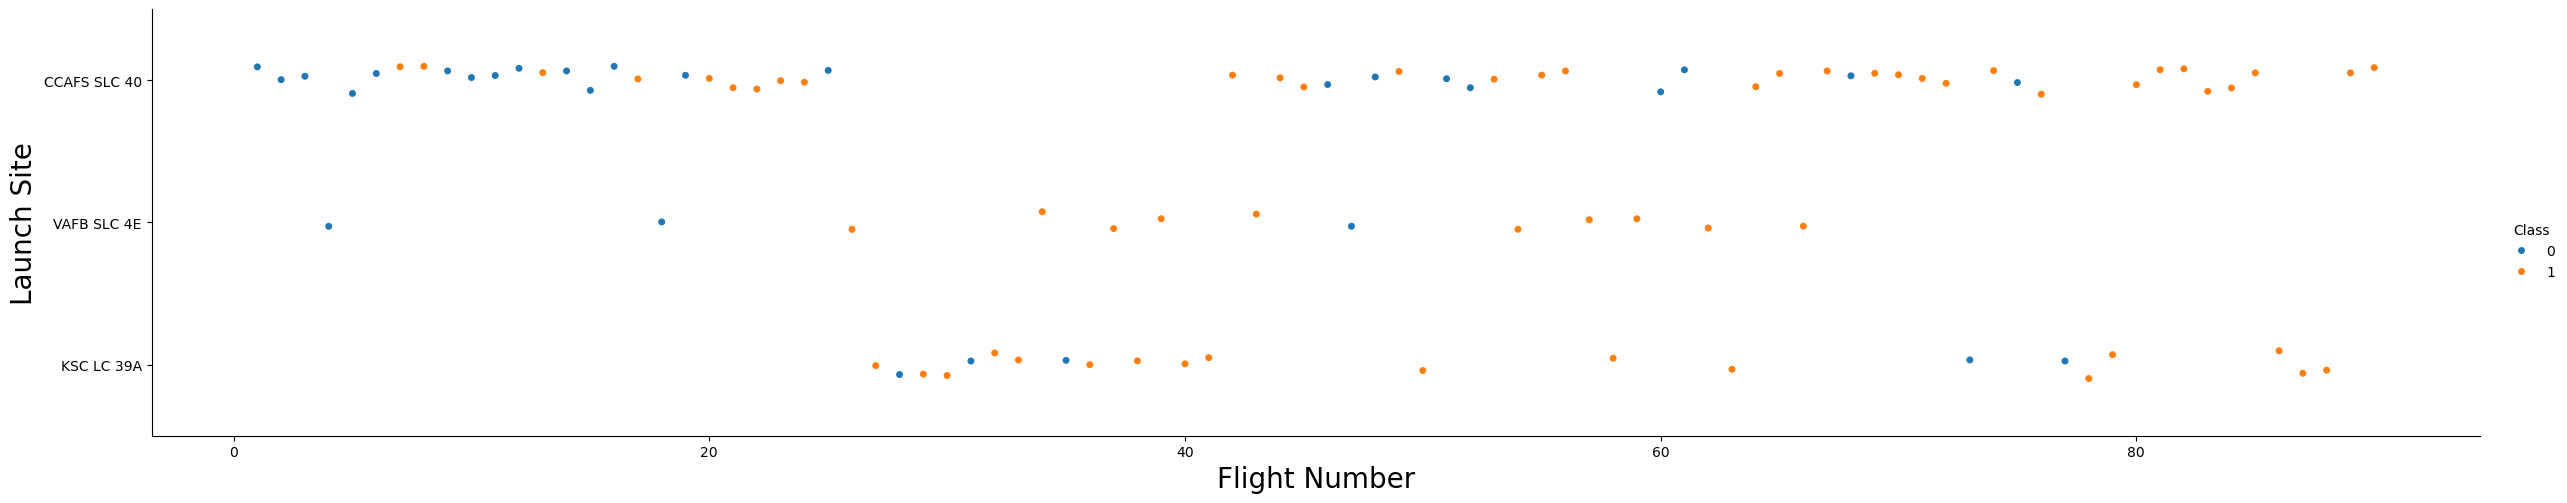

In [6]:
sns.catplot(y="LaunchSite", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20)
plt.ylabel("Launch Site", fontsize=20)
plt.show()

## Task 2: Relationship between Payload Mass and Launch Site

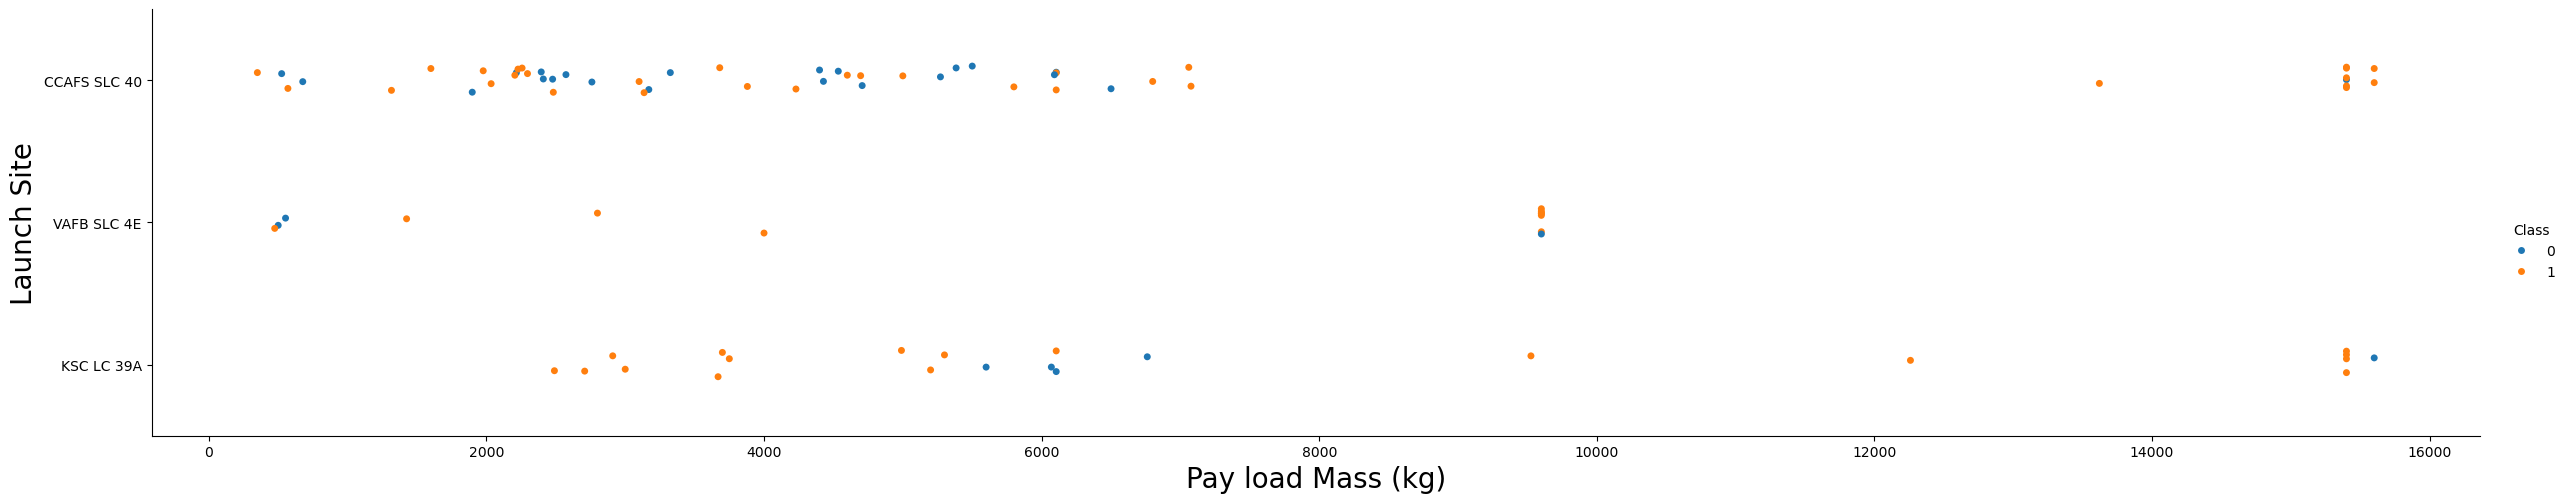

In [7]:
sns.catplot(y="LaunchSite", x="PayloadMass", hue="Class", data=df, aspect=5)
plt.xlabel("Pay load Mass (kg)", fontsize=20)
plt.ylabel("Launch Site", fontsize=20)
plt.show()

## Task 3: Success rate of each orbit type

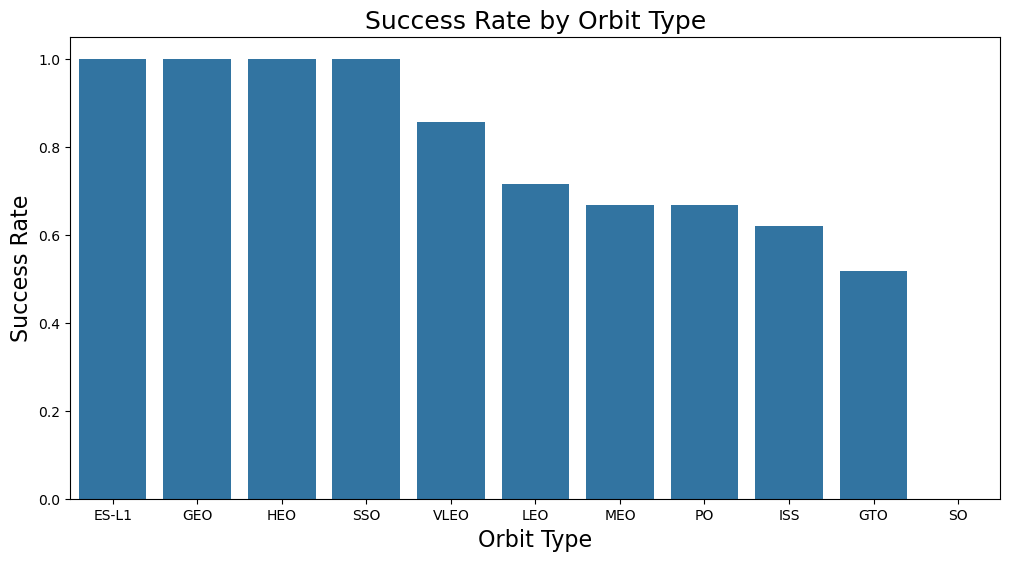

,Orbit,Class
0,ES-L1,1.000000
1,GEO,1.000000
2,HEO,1.000000
3,SSO,1.000000
4,VLEO,0.857143
5,LEO,0.714286
6,MEO,0.666667
7,PO,0.666667
8,ISS,0.619048
9,GTO,0.518519


In [8]:
orbit_success = df.groupby('Orbit')['Class'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(x='Orbit', y='Class', data=orbit_success)
plt.xlabel("Orbit Type", fontsize=16)
plt.ylabel("Success Rate", fontsize=16)
plt.title("Success Rate by Orbit Type", fontsize=18)
plt.show()
orbit_success

## Task 4: Relationship between Flight Number and Orbit type

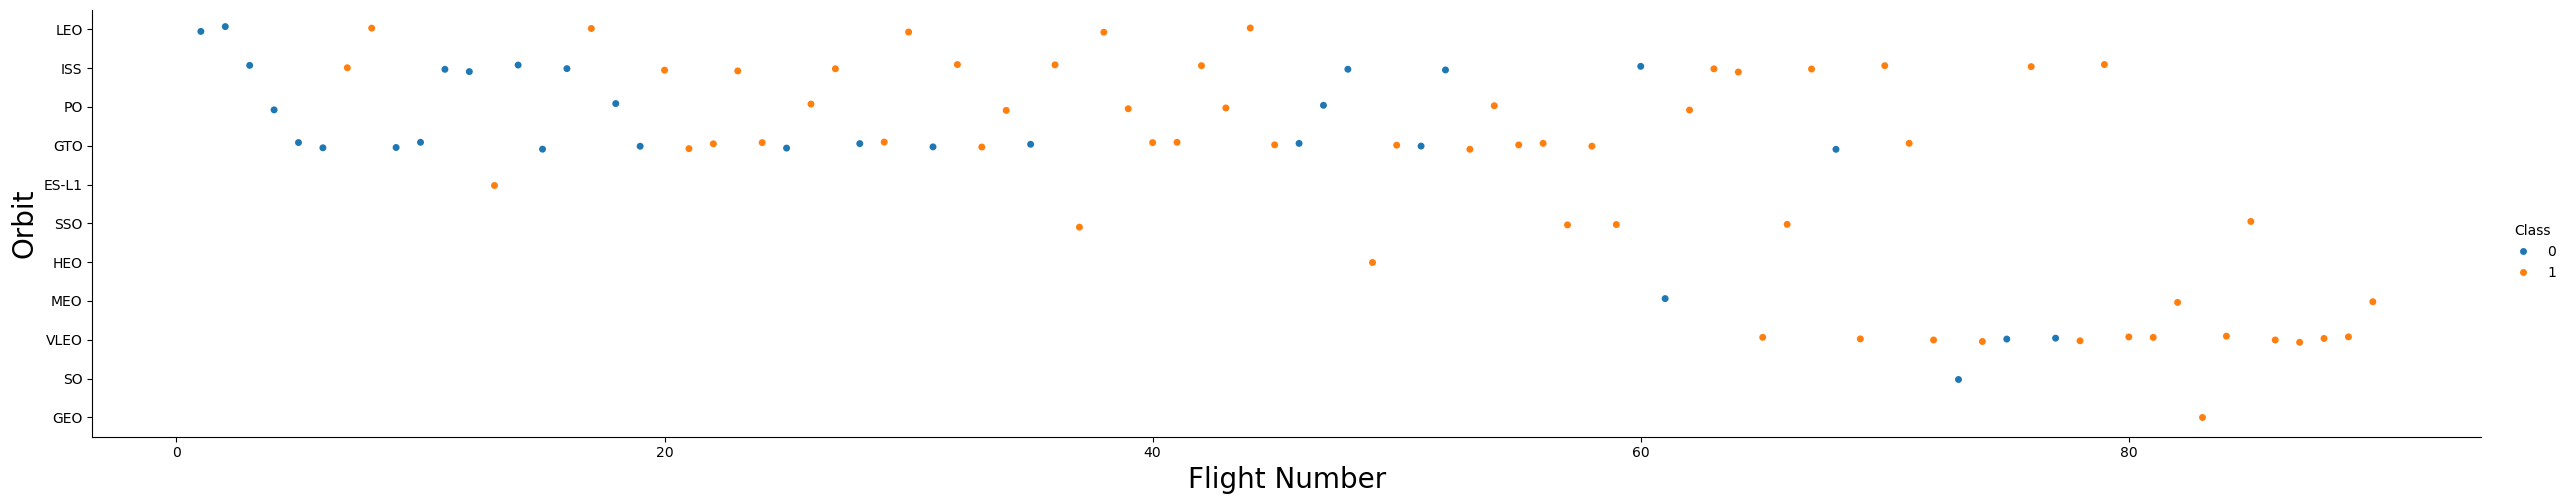

In [9]:
sns.catplot(y="Orbit", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20)
plt.ylabel("Orbit", fontsize=20)
plt.show()

## Task 5: Relationship between Payload Mass and Orbit type

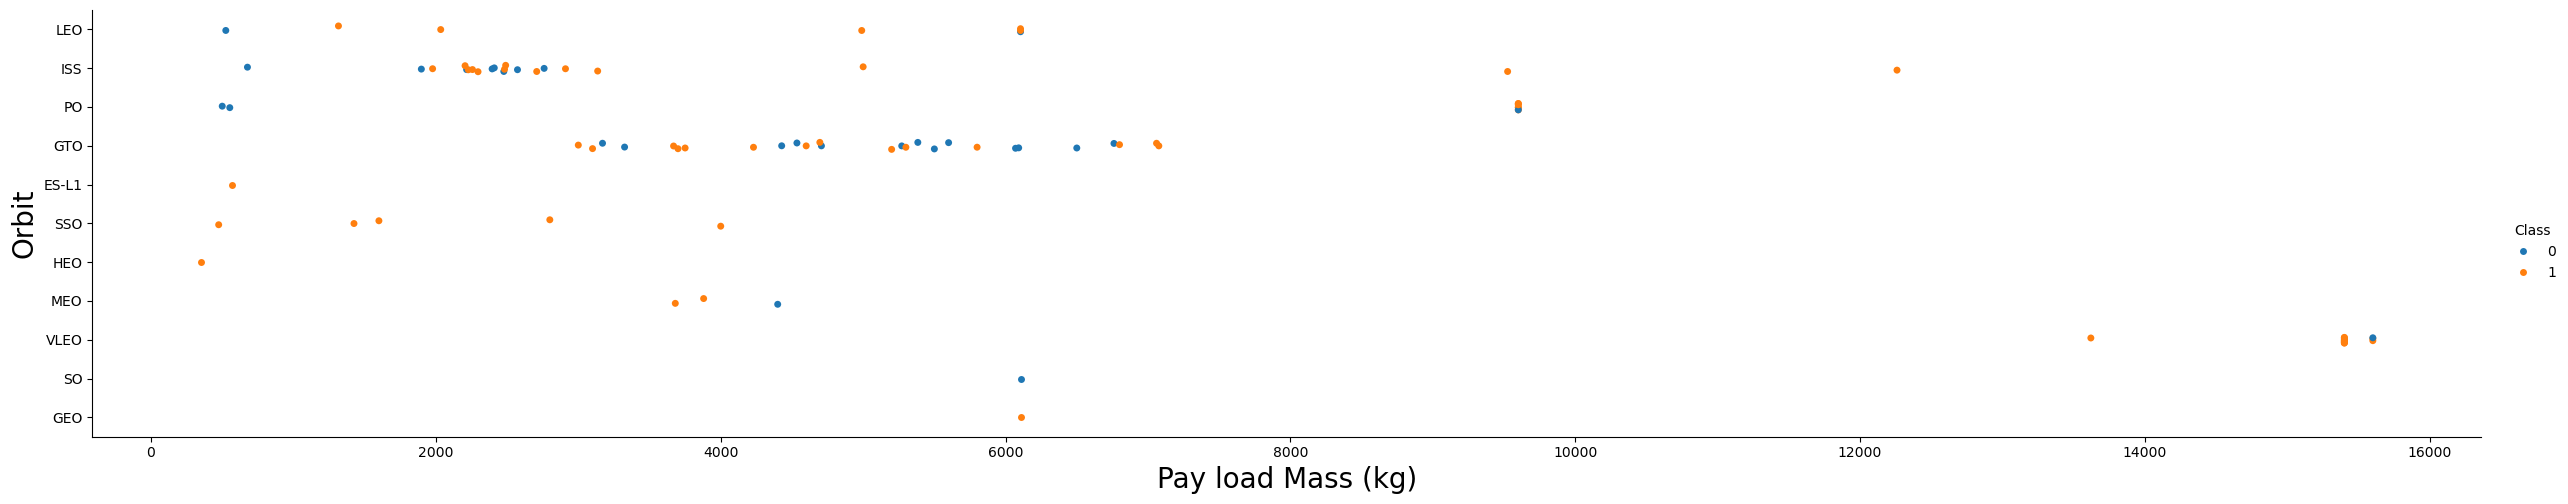

In [10]:
sns.catplot(y="Orbit", x="PayloadMass", hue="Class", data=df, aspect=5)
plt.xlabel("Pay load Mass (kg)", fontsize=20)
plt.ylabel("Orbit", fontsize=20)
plt.show()

## Task 6: Launch success yearly trend

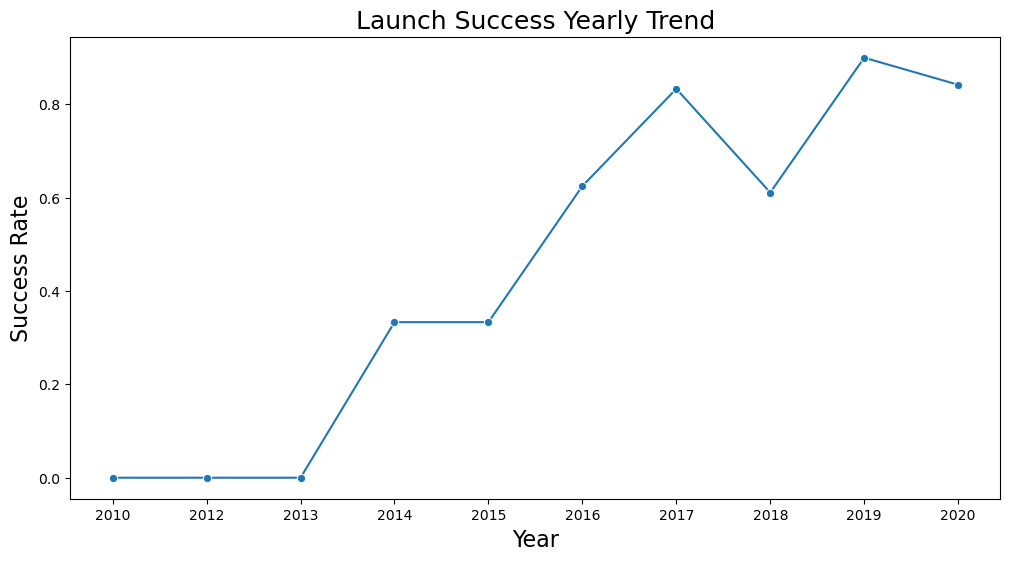

,Year,Class
0,2010,0.000000
1,2012,0.000000
2,2013,0.000000
3,2014,0.333333
4,2015,0.333333
5,2016,0.625000
6,2017,0.833333
7,2018,0.611111
8,2019,0.900000
9,2020,0.842105


In [11]:
def Extract_year(dates):
    return [str(d).split("-")[0] for d in dates]

df['Year'] = Extract_year(df['Date'])
yearly = df.groupby('Year')['Class'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(x='Year', y='Class', data=yearly, marker='o')
plt.xlabel("Year", fontsize=16)
plt.ylabel("Success Rate", fontsize=16)
plt.title("Launch Success Yearly Trend", fontsize=18)
plt.show()
yearly

The success rate has kept increasing since 2013 (with a dip in 2018) until 2020.

## Features Engineering

In [12]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused',
               'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


## Task 7: Create dummy variables for categorical columns

In [13]:
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6104.959412,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2,525.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,3,677.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4,500.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,3170.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False


## Task 8: Cast all numeric columns to `float64`

In [14]:
features_one_hot = features_one_hot.astype('float64')
print(features_one_hot.shape)
features_one_hot.to_csv('dataset_part_3.csv', index=False)

(90, 80)


## Author

Jhoselyn Vera